In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
df = pd.read_csv("final_df.csv", low_memory=False)

In [5]:
df.head()

,Log_ID,TBM_Timestamp,Tunnel_Section,Contractor_Name,Target_Advance_Rate,Is_Spoofed,sensor_hex,torque_knm,pressure_bar,thermal_c,status
0,TBM-LOG-0000002,2023-01-01 00:00:00+00:00,HighSpeed_Rail_Link,Apex_Drilling,5.425898,0,TBM-SENS-5410,616.23,157.66,40.50,OK
1,TBM-LOG-0000007,2023-01-01 00:05:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,2.993575,0,TBM-SENS-8004,726.42,288.80,62.57,OK
2,TBM-LOG-0000014,2023-01-01 00:12:00+00:00,HighSpeed_Rail_Link,Titan_Excavators,2.742072,0,TBM-SENS-8906,1071.80,163.74,43.00,OK
3,TBM-LOG-0000023,2023-01-01 00:24:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,4.853213,0,TBM-SENS-2693,733.66,158.25,41.85,OK
4,TBM-LOG-0000027,2023-01-01 00:27:00+00:00,HighSpeed_Rail_Link,Global_Tunnels,3.534157,0,TBM-SENS-1710,849.03,262.47,57.20,OK


In [6]:
df.dtypes

Log_ID                     str
TBM_Timestamp              str
Tunnel_Section             str
Contractor_Name            str
Target_Advance_Rate    float64
Is_Spoofed               int64
sensor_hex                 str
torque_knm             float64
pressure_bar           float64
thermal_c              float64
status                     str
dtype: object

- Lost the float32 conversion from float64 because of CSV File.

In [7]:
float_cols = df.select_dtypes(include=["float64"]).columns
df[float_cols] = df[float_cols].astype("float32")

In [8]:
df.dtypes

Log_ID                     str
TBM_Timestamp              str
Tunnel_Section             str
Contractor_Name            str
Target_Advance_Rate    float32
Is_Spoofed               int64
sensor_hex                 str
torque_knm             float32
pressure_bar           float32
thermal_c              float32
status                     str
dtype: object

- Coverting to datetime formate

In [9]:
df['TBM_Timestamp'] = pd.to_datetime(df['TBM_Timestamp'], errors='coerce')

In [10]:
df.dtypes

Log_ID                                 str
TBM_Timestamp          datetime64[us, UTC]
Tunnel_Section                         str
Contractor_Name                        str
Target_Advance_Rate                float32
Is_Spoofed                           int64
sensor_hex                             str
torque_knm                         float32
pressure_bar                       float32
thermal_c                          float32
status                                 str
dtype: object

In [11]:
df.head()

,Log_ID,TBM_Timestamp,Tunnel_Section,Contractor_Name,Target_Advance_Rate,Is_Spoofed,sensor_hex,torque_knm,pressure_bar,thermal_c,status
0,TBM-LOG-0000002,2023-01-01 00:00:00+00:00,HighSpeed_Rail_Link,Apex_Drilling,5.425898,0,TBM-SENS-5410,616.229980,157.660004,40.500000,OK
1,TBM-LOG-0000007,2023-01-01 00:05:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,2.993575,0,TBM-SENS-8004,726.419983,288.799988,62.570000,OK
2,TBM-LOG-0000014,2023-01-01 00:12:00+00:00,HighSpeed_Rail_Link,Titan_Excavators,2.742072,0,TBM-SENS-8906,1071.800049,163.740005,43.000000,OK
3,TBM-LOG-0000023,2023-01-01 00:24:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,4.853213,0,TBM-SENS-2693,733.659973,158.250000,41.849998,OK
4,TBM-LOG-0000027,2023-01-01 00:27:00+00:00,HighSpeed_Rail_Link,Global_Tunnels,3.534157,0,TBM-SENS-1710,849.030029,262.470001,57.200001,OK


In [14]:
df.nunique()

Log_ID                 1000000
TBM_Timestamp           393335
Tunnel_Section               4
Contractor_Name              4
Target_Advance_Rate     943135
Is_Spoofed                   2
sensor_hex                8999
torque_knm              112269
pressure_bar             29158
thermal_c                 2501
status                       2
dtype: int64

In [16]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex              20077
torque_knm              20077
pressure_bar           167274
thermal_c              167274
status                  20077
dtype: int64

In [17]:
df['torque_knm']

0          616.229980
1          726.419983
2         1071.800049
3          733.659973
4          849.030029
             ...     
999995    1136.880005
999996     685.650024
999997    1056.969971
999998     970.780029
999999     512.820007
Name: torque_knm, Length: 1000000, dtype: float32

In [19]:
torque = df['torque_knm']
is_nan = torque.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('torque_knm', lambda x: x.index.min()),
        end_index=('torque_knm', lambda x: x.index.max()),
        missing_count=('torque_knm', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

            start_index  end_index  missing_count
torque_knm                                       
8956             229295     229297              3
18772            475087     475089              3
16930            429782     429784              3
5384             140139     140141              3
39060            991279     991281              3
...                 ...        ...            ...
50                 1228       1228              1
52                 1234       1234              1
54                 1281       1281              1
56                 1308       1308              1
20                  550        550              1

[19693 rows x 3 columns]


In [20]:
df["torque_knm"] = (df["torque_knm"].interpolate(method="linear").bfill().ffill())

In [21]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex              20077
torque_knm                  0
pressure_bar           167274
thermal_c              167274
status                  20077
dtype: int64

In [22]:
sensor = df['sensor_hex']
is_nan = sensor.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('sensor_hex', lambda x: x.index.min()),
        end_index=('sensor_hex', lambda x: x.index.max()),
        missing_count=('sensor_hex', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

            start_index  end_index  missing_count
sensor_hex                                       
8956             229295     229297              3
18772            475087     475089              3
16930            429782     429784              3
5384             140139     140141              3
39060            991279     991281              3
...                 ...        ...            ...
50                 1228       1228              1
52                 1234       1234              1
54                 1281       1281              1
56                 1308       1308              1
20                  550        550              1

[19693 rows x 3 columns]


In [23]:
df['sensor_hex']

0         TBM-SENS-5410
1         TBM-SENS-8004
2         TBM-SENS-8906
3         TBM-SENS-2693
4         TBM-SENS-1710
              ...      
999995    TBM-SENS-8391
999996    TBM-SENS-8298
999997    TBM-SENS-7431
999998    TBM-SENS-1889
999999    TBM-SENS-4191
Name: sensor_hex, Length: 1000000, dtype: str

In [24]:
df["sensor_hex"] = df["sensor_hex"].fillna("UNKNOWN")

In [25]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex                  0
torque_knm                  0
pressure_bar           167274
thermal_c              167274
status                  20077
dtype: int64

In [26]:
time = df['TBM_Timestamp']
is_nan = time.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('TBM_Timestamp', lambda x: x.index.min()),
        end_index=('TBM_Timestamp', lambda x: x.index.max()),
        missing_count=('TBM_Timestamp', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

               start_index  end_index  missing_count
TBM_Timestamp                                       
6                   625537     750899         125363
4                   375771     500985         125215
2                   124659     249561         124903
8                   875136     999999         124864


In [27]:
valid_time = df["TBM_Timestamp"].dropna().sort_values()
diffs = valid_time.diff().dropna()
print(diffs.value_counts().head(20))

TBM_Timestamp
0 days 00:01:00    154815
0 days 00:00:00    106320
0 days 00:02:00     93735
0 days 00:03:00     56927
0 days 00:04:00     34734
0 days 00:05:00     20754
0 days 00:06:00     12638
0 days 00:07:00      7859
0 days 00:08:00      4663
0 days 00:09:00      2794
0 days 00:10:00      1711
0 days 00:11:00      1029
0 days 00:12:00       662
0 days 00:13:00       439
0 days 00:14:00       245
0 days 00:15:00       132
0 days 00:16:00        81
0 days 00:17:00        43
0 days 00:18:00        29
0 days 00:19:00        22
Name: count, dtype: int64


In [28]:
df["TBM_Timestamp"].dtypes

datetime64[us, UTC]

- Irregular gap b/w timestamp.
- Lots of duplicates values in Timestamps.
- Half of the data in timestaps is Missing/NaT.
- Need to do later before fourier transformation.

In [30]:
df_time = df.dropna(subset=["TBM_Timestamp"]).copy()
df_time = df_time.sort_values(["Tunnel_Section", "TBM_Timestamp"])
df_time["time_diff"] = (df_time.groupby("Tunnel_Section")["TBM_Timestamp"].diff())

- We have sorted the data according to timestapms and tunnel section.
- Now we Find out the time_differnce.

In [36]:
print(df_time["time_diff"].dropna().value_counts().head(20))

time_diff
0 days 00:01:00    55310
0 days 00:02:00    48535
0 days 00:03:00    43003
0 days 00:04:00    37924
0 days 00:05:00    33315
0 days 00:00:00    29936
0 days 00:06:00    29542
0 days 00:07:00    26162
0 days 00:08:00    22934
0 days 00:09:00    20315
0 days 00:10:00    17922
0 days 00:11:00    15739
0 days 00:12:00    13989
0 days 00:13:00    12322
0 days 00:14:00    10865
0 days 00:15:00     9682
0 days 00:16:00     8471
0 days 00:17:00     7543
0 days 00:18:00     6607
0 days 00:19:00     5901
Name: count, dtype: int64


- We are soring the timedifference is greater than 1.

In [32]:
positive_diff = df_time.loc[df_time["time_diff"] > pd.Timedelta(0),"time_diff"]
print(positive_diff.value_counts().head(20))

time_diff
0 days 00:01:00    55310
0 days 00:02:00    48535
0 days 00:03:00    43003
0 days 00:04:00    37924
0 days 00:05:00    33315
0 days 00:06:00    29542
0 days 00:07:00    26162
0 days 00:08:00    22934
0 days 00:09:00    20315
0 days 00:10:00    17922
0 days 00:11:00    15739
0 days 00:12:00    13989
0 days 00:13:00    12322
0 days 00:14:00    10865
0 days 00:15:00     9682
0 days 00:16:00     8471
0 days 00:17:00     7543
0 days 00:18:00     6607
0 days 00:19:00     5901
0 days 00:20:00     5191
Name: count, dtype: int64


In [33]:
def get_sampling_interval(group):
    diff = group["TBM_Timestamp"].diff().dropna()
    diff = diff[diff > pd.Timedelta(0)]

    if diff.empty:
        return pd.NaT

    return diff.mode().iloc[0]

In [34]:
sampling_intervals = (df_time.groupby("Tunnel_Section").apply(get_sampling_interval))

In [35]:
print(sampling_intervals)

Tunnel_Section
HighSpeed_Rail_Link   0 days 00:01:00
Metro_Line_A          0 days 00:01:00
Metro_Line_B          0 days 00:01:00
Undersea_Cable_Core   0 days 00:01:00
dtype: timedelta64[us]


- We get Sample_rate is 1 Minutes

### We must process the torque signal. Apply a Fast Fourier Transform (FFT) to a sample sequence of 'torque_knm'.

In [37]:
sampling_interval = 60       # seconds/sample
sampling_rate = 1 / 60       # Hz

In [38]:
# Convert back to a NumPy array
torque = df["torque_knm"].to_numpy()

In [39]:
# Apply FFT
fft_result = np.fft.rfft(torque)

# Compute frequency bins          
freqs = np.fft.rfftfreq(torque.size, d=1.0/sampling_rate)
#if you want the magnitude spectrum, take the absolute value:

magnitude = np.abs(fft_result)
#you can plot it to inspect the frequency content:

### Plot the FFT Frequency Spectrum. Observe the massive synthetic high-frequency spike injected by the cartel.

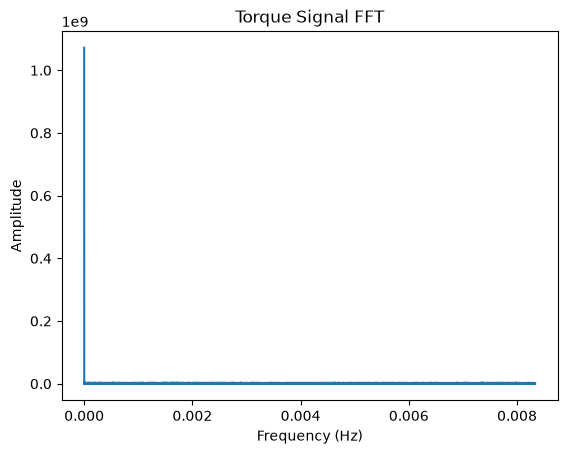

In [40]:
plt.plot(freqs, magnitude)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.title('Torque Signal FFT')
plt.show()

### Time-Series Deep Learning requires 3D tensors: [samples, time_steps, features].

In [42]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex                  0
torque_knm                  0
pressure_bar           167274
thermal_c              167274
status                  20077
dtype: int64

In [43]:
df.dtypes

Log_ID                                 str
TBM_Timestamp          datetime64[us, UTC]
Tunnel_Section                         str
Contractor_Name                        str
Target_Advance_Rate                float32
Is_Spoofed                           int64
sensor_hex                             str
torque_knm                         float32
pressure_bar                       float32
thermal_c                          float32
status                                 str
dtype: object

#### Filling missing value in the Pressure_bar

In [44]:
df['pressure_bar']

0         157.660004
1         288.799988
2         163.740005
3         158.250000
4         262.470001
             ...    
999995    172.789993
999996    199.130005
999997    195.960007
999998    236.440002
999999    225.300003
Name: pressure_bar, Length: 1000000, dtype: float32

In [46]:
pressure = df['pressure_bar']
is_nan = pressure.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('pressure_bar', lambda x: x.index.min()),
        end_index=('pressure_bar', lambda x: x.index.max()),
        missing_count=('pressure_bar', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

              start_index  end_index  missing_count
pressure_bar                                       
115234             411238     411245              8
180706             647015     647021              7
161322             577015     577021              7
151916             543285     543291              7
137618             491340     491345              6
...                   ...        ...            ...
278670             999839     999839              1
278666             999830     999830              1
278664             999823     999823              1
278660             999801     999801              1
34                     89         89              1

[139351 rows x 3 columns]


In [47]:
df["pressure_bar"] = df["pressure_bar"].interpolate(method="linear",limit_direction="both")

#### Filling the missing value in the thermal_c

In [48]:
thermal = df['thermal_c']
is_nan = thermal.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('thermal_c', lambda x: x.index.min()),
        end_index=('thermal_c', lambda x: x.index.max()),
        missing_count=('thermal_c', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

           start_index  end_index  missing_count
thermal_c                                       
115234          411238     411245              8
180706          647015     647021              7
161322          577015     577021              7
151916          543285     543291              7
137618          491340     491345              6
...                ...        ...            ...
278670          999839     999839              1
278666          999830     999830              1
278664          999823     999823              1
278660          999801     999801              1
34                  89         89              1

[139351 rows x 3 columns]


In [49]:
df["thermal_c"] = df["thermal_c"].interpolate(method="linear",limit_direction="both")

In [50]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex                  0
torque_knm                  0
pressure_bar                0
thermal_c                   0
status                  20077
dtype: int64

#### Filling missing value in status 

In [51]:
df['status'].value_counts()

status
OK      832726
WARN    147197
Name: count, dtype: int64

In [52]:
print(df["status"].value_counts(dropna=False))

status
OK      832726
WARN    147197
NaN      20077
Name: count, dtype: int64


In [53]:
status = df['status']
is_nan = status.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('status', lambda x: x.index.min()),
        end_index=('status', lambda x: x.index.max()),
        missing_count=('status', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

        start_index  end_index  missing_count
status                                       
8956         229295     229297              3
18772        475087     475089              3
16930        429782     429784              3
5384         140139     140141              3
39060        991279     991281              3
...             ...        ...            ...
50             1228       1228              1
52             1234       1234              1
54             1281       1281              1
56             1308       1308              1
20              550        550              1

[19693 rows x 3 columns]


In [54]:
df["status"] = df["status"].ffill().bfill()

#### Now Only Timestamp is remaining.

In [55]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex                  0
torque_knm                  0
pressure_bar                0
thermal_c                   0
status                      0
dtype: int64

In [56]:
df.dtypes

Log_ID                                 str
TBM_Timestamp          datetime64[us, UTC]
Tunnel_Section                         str
Contractor_Name                        str
Target_Advance_Rate                float32
Is_Spoofed                           int64
sensor_hex                             str
torque_knm                         float32
pressure_bar                       float32
thermal_c                          float32
status                                 str
dtype: object

In [57]:
time = df['TBM_Timestamp']
is_nan = time.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('TBM_Timestamp', lambda x: x.index.min()),
        end_index=('TBM_Timestamp', lambda x: x.index.max()),
        missing_count=('TBM_Timestamp', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

               start_index  end_index  missing_count
TBM_Timestamp                                       
6                   625537     750899         125363
4                   375771     500985         125215
2                   124659     249561         124903
8                   875136     999999         124864


In [60]:
print(df.loc[124650:124670, "TBM_Timestamp"])
print(df.loc[249550:249570, "TBM_Timestamp"])

124650   2024-11-25 09:51:00+00:00
124651   2024-11-25 09:57:00+00:00
124652   2024-11-25 09:59:00+00:00
124653   2024-11-25 10:03:00+00:00
124654   2024-11-25 10:05:00+00:00
124655   2024-11-25 10:12:00+00:00
124656   2024-11-25 10:17:00+00:00
124657   2024-11-25 10:23:00+00:00
124658   2024-11-25 10:29:00+00:00
124659                         NaT
124660                         NaT
124661                         NaT
124662                         NaT
124663                         NaT
124664                         NaT
124665                         NaT
124666                         NaT
124667                         NaT
124668                         NaT
124669                         NaT
124670                         NaT
Name: TBM_Timestamp, dtype: datetime64[us, UTC]
249550                         NaT
249551                         NaT
249552                         NaT
249553                         NaT
249554                         NaT
249555                         NaT
249556 

In [63]:
print(df.loc[625530:625545, "TBM_Timestamp"])
print(df.loc[750895:750905, "TBM_Timestamp"])

625530   2024-11-25 09:58:00+00:00
625531   2024-11-25 09:59:00+00:00
625532   2024-11-25 10:04:00+00:00
625533   2024-11-25 10:21:00+00:00
625534   2024-11-25 10:23:00+00:00
625535   2024-11-25 10:29:00+00:00
625536   2024-11-25 10:32:00+00:00
625537                         NaT
625538                         NaT
625539                         NaT
625540                         NaT
625541                         NaT
625542                         NaT
625543                         NaT
625544                         NaT
625545                         NaT
Name: TBM_Timestamp, dtype: datetime64[us, UTC]
750895                         NaT
750896                         NaT
750897                         NaT
750898                         NaT
750899                         NaT
750900   2023-01-01 00:06:00+00:00
750901   2023-01-01 00:59:00+00:00
750902   2023-01-01 00:59:00+00:00
750903   2023-01-01 01:00:00+00:00
750904   2023-01-01 01:20:00+00:00
750905   2023-01-01 01:38:00+00:00
Name: T

In [64]:
df.columns

Index(['Log_ID', 'TBM_Timestamp', 'Tunnel_Section', 'Contractor_Name',
       'Target_Advance_Rate', 'Is_Spoofed', 'sensor_hex', 'torque_knm',
       'pressure_bar', 'thermal_c', 'status'],
      dtype='str')

In [66]:
print(df["Tunnel_Section"].nunique())
print(df.groupby("Tunnel_Section")["TBM_Timestamp"].agg(["min", "max", "count"]))

4
                                          min                       max  \
Tunnel_Section                                                            
HighSpeed_Rail_Link 2023-01-01 00:00:00+00:00 2024-11-25 10:29:00+00:00   
Metro_Line_A        2023-01-01 00:11:00+00:00 2024-11-25 10:36:00+00:00   
Metro_Line_B        2023-01-01 00:03:00+00:00 2024-11-25 10:32:00+00:00   
Undersea_Cable_Core 2023-01-01 00:06:00+00:00 2024-11-25 10:28:00+00:00   

                      count  
Tunnel_Section               
HighSpeed_Rail_Link  124659  
Metro_Line_A         126209  
Metro_Line_B         124551  
Undersea_Cable_Core  124236  


In [67]:
df.head()

,Log_ID,TBM_Timestamp,Tunnel_Section,Contractor_Name,Target_Advance_Rate,Is_Spoofed,sensor_hex,torque_knm,pressure_bar,thermal_c,status
0,TBM-LOG-0000002,2023-01-01 00:00:00+00:00,HighSpeed_Rail_Link,Apex_Drilling,5.425898,0,TBM-SENS-5410,616.229980,157.660004,40.500000,OK
1,TBM-LOG-0000007,2023-01-01 00:05:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,2.993575,0,TBM-SENS-8004,726.419983,288.799988,62.570000,OK
2,TBM-LOG-0000014,2023-01-01 00:12:00+00:00,HighSpeed_Rail_Link,Titan_Excavators,2.742072,0,TBM-SENS-8906,1071.800049,163.740005,43.000000,OK
3,TBM-LOG-0000023,2023-01-01 00:24:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,4.853213,0,TBM-SENS-2693,733.659973,158.250000,41.849998,OK
4,TBM-LOG-0000027,2023-01-01 00:27:00+00:00,HighSpeed_Rail_Link,Global_Tunnels,3.534157,0,TBM-SENS-1710,849.030029,262.470001,57.200001,OK


In [69]:
df.to_parquet(
    "df_final_processed.parquet",
    engine="pyarrow",
    index=False
)


print("Saved:", "df_final_processed.parquet")
print("Shape:", df.shape)

Saved: df_final_processed.parquet
Shape: (1000000, 11)


#### We need to first deal with the timestamp missing value because it is very sensetive to fill 
#### Eveen After doing EDA I would not reach the conclusion.
### We will do next day.